# 02 · Naive Bayes categórico para la clase ICA del día siguiente

**Técnica de la Parte 1:** un clasificador Naive Bayes implementado desde cero en `src/model.py` (numpy, sin librerías de aprendizaje automático).

$$P(y \mid x_1,\dots,x_d) \;\propto\; P(y)\prod_{j=1}^{d} P(x_j \mid y), \qquad \hat P(x_j = v \mid y = c) = \frac{N_{cjv} + \alpha}{N_c + \alpha V_j}$$

- $N_c$: días de entrenamiento con clase $c$; $N_{cjv}$: de esos, cuántos tienen la variable $j$ con valor $v$; $V_j$: número de valores posibles de la variable $j$.
- $\alpha$ es el suavizado de Laplace: evita probabilidades cero para combinaciones nunca vistas.
- Se predice la clase con mayor probabilidad posterior, sumando logaritmos.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, features, ica, preprocess

plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

from src import train
from src.model import NaiveBayesCategorico, exactitud, predecir_persistencia

diario = preprocess.cargar_diario()
tabla = features.construir_tabla(diario).dropna(subset=["y"])
corte = pd.Timestamp(config.TEST_DESDE)
entrenamiento, prueba = tabla[tabla["fecha_objetivo"] < corte], tabla[tabla["fecha_objetivo"] >= corte]
print(f"Entrenamiento: {len(entrenamiento):,} filas, hasta {entrenamiento['fecha_objetivo'].max():%Y-%m-%d}")
print(f"Prueba:        {len(prueba):,} filas, desde {prueba['fecha_objetivo'].min():%Y-%m-%d}")
tabla[["estacion", "fecha", "pm25_hoy", "pm25_semana", "cambio_valle_ug", *features.NOMBRES, "y"]].head()

Entrenamiento: 12,883 filas, hasta 2024-12-31
Prueba:        7,682 filas, desde 2025-01-01


,estacion,fecha,pm25_hoy,pm25_semana,cambio_valle_ug,nivel_hoy,nivel_semana,dia_manana,cambio_valle,y
0,ALMACÉN GENERAL DE EPM,2023-12-01,19.0,19.0,4.4,5,5,1,4,1.0
1,ALMACÉN GENERAL DE EPM,2023-12-02,16.9,18.0,-2.4,4,5,2,1,1.0
2,ALMACÉN GENERAL DE EPM,2023-12-03,16.0,17.3,-0.4,4,5,0,2,1.0
4,ALMACÉN GENERAL DE EPM,2023-12-07,24.9,19.1,1.0,7,5,0,2,1.0
5,ALMACÉN GENERAL DE EPM,2023-12-08,18.0,18.9,-6.3,5,5,1,0,1.0


## 1. Variables

Cada variable es categórica y solo usa información disponible el día *t* para predecir el día *t+1*.

In [2]:
pd.set_option("display.max_colwidth", 200)
pd.DataFrame([{"variable": k, "niveles": len(v), "valores": ", ".join(v)} for k, v in features.VARIABLES.items()])

,variable,niveles,valores
0,nivel_hoy,14,"0-7, 8-10, 11-12, 13-14, 15-16, 17-19, 20-23, 24-27, 28-32, 33-37, 38-41, 42-47, 48-55, 56 o más"
1,nivel_semana,14,"0-7, 8-10, 11-12, 13-14, 15-16, 17-19, 20-23, 24-27, 28-32, 33-37, 38-41, 42-47, 48-55, 56 o más"
2,dia_manana,3,"laboral, sábado, domingo"
3,cambio_valle,5,"baja fuerte, baja, estable, sube, sube fuerte"


## 2. Entrenamiento y comparación con las líneas base

Protocolo (`src/train.py`):

1. **Partición temporal.** Entrenamiento con días objetivo hasta el 2024-12-31; prueba con todo 2025.
2. **Validación.** Dentro del entrenamiento, el último año (2024) se reserva para elegir α y el conjunto de variables.
3. **Prueba.** Con α elegido se reentrena con todo el entrenamiento y se evalúa una sola vez en 2025.

Líneas base: **clase mayoritaria** (siempre la más frecuente) y **persistencia** (mañana igual que hoy). «Episodio» = Dañina para grupos sensibles o peor.

In [3]:
nb_modelo, metricas = train.entrenar(diario)
print(f"α elegido en validación: {metricas['alpha']}")
print(f"Clases en prueba: {metricas['particion']['prueba']['clases']}")

def tabla_resultados(resultados):
    return pd.DataFrame(resultados).T.drop(columns="matriz_confusion").astype(float)

print("\nPRUEBA (2025)")
display(tabla_resultados(metricas["resultados"]))
v = metricas["validacion"]
print(f"VALIDACIÓN ({v['periodo']['desde']} a {v['periodo']['hasta']}; clases: {v['periodo']['clases']})")
tabla_resultados(v["resultados"])

α elegido en validación: 0.1
Clases en prueba: {'Buena': 2809, 'Aceptable': 4867, 'Dañina para grupos sensibles': 6, 'Dañina o peor': 0}

PRUEBA (2025)


,exactitud,f1_macro,precision_episodio,recall_episodio
Clase mayoritaria,0.6336,0.2586,0.0000,0.0000
Persistencia,0.7816,0.5103,0.0000,0.0000
Naive Bayes (propio),0.7915,0.5504,0.0588,0.1667


VALIDACIÓN (2024-01-02 a 2024-12-31; clases: {'Buena': 1751, 'Aceptable': 5507, 'Dañina para grupos sensibles': 199, 'Dañina o peor': 1})


,exactitud,f1_macro,precision_episodio,recall_episodio
Clase mayoritaria,0.7384,0.2124,0.0000,0.000
Persistencia,0.8037,0.5139,0.5594,0.565
Naive Bayes (propio),0.8109,0.5195,0.4717,0.625


**Cómo leer las dos tablas.**

- La de **prueba** es la cifra honesta de generalización, pero 2025 solo tiene 6 días de episodio entre más de 7.000: la precisión y el recall de episodio de esa tabla no son estimables (un acierto de más o de menos los cambia por completo).
- La de **validación** sí tiene unos 200 días de episodio, pero ese año se usó para elegir α y las variables, así que sus cifras son optimistas.

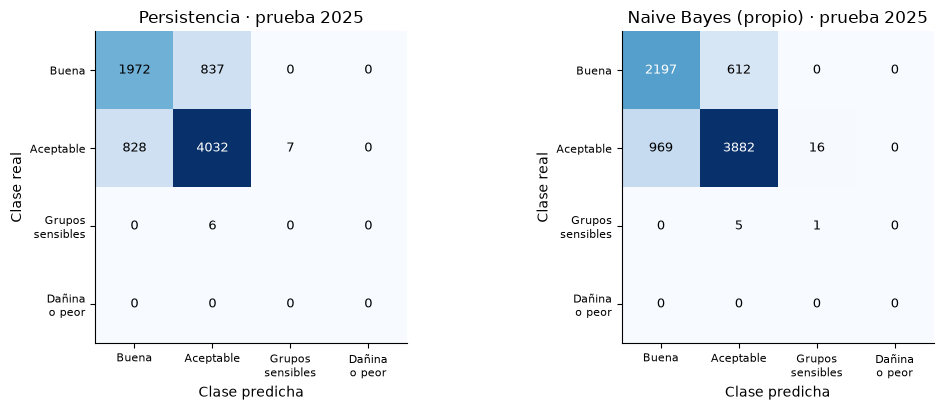

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
cortas = ["Buena", "Aceptable", "Grupos\nsensibles", "Dañina\no peor"]
for ax, nombre in zip(ejes, ["Persistencia", "Naive Bayes (propio)"]):
    m = np.array(metricas["resultados"][nombre]["matriz_confusion"])
    ax.imshow(m, cmap="Blues")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else "black", fontsize=9)
    ax.set_xticks(range(4)); ax.set_xticklabels(cortas, fontsize=8); ax.set_yticks(range(4)); ax.set_yticklabels(cortas, fontsize=8)
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real"); ax.set_title(f"{nombre} · prueba 2025"); ax.grid(False)
plt.tight_layout(); plt.show()

## 3. ¿Es real la diferencia con la persistencia?

La diferencia de exactitud es pequeña. Para saber si podría deberse al azar se hace un *bootstrap* por bloques: se remuestrean **días completos** (no filas sueltas, porque las estaciones de un mismo día están correlacionadas) y se recalcula la diferencia 2.000 veces.

In [5]:
X_te, y_te = features.matriz_X(prueba), prueba["y"].to_numpy(int)
acierto_nb = nb_modelo.predict(X_te) == y_te
acierto_pe = predecir_persistencia(prueba["clase_hoy"]) == y_te

por_dia = pd.DataFrame({"fecha": prueba["fecha_objetivo"].to_numpy(), "nb": acierto_nb, "pe": acierto_pe}).groupby("fecha").agg(nb=("nb", "sum"), pe=("pe", "sum"), n=("nb", "size"))
rng = np.random.default_rng(0)
diferencias = []
for _ in range(2000):
    muestra = por_dia.iloc[rng.integers(0, len(por_dia), len(por_dia))]
    diferencias.append((muestra["nb"].sum() - muestra["pe"].sum()) / muestra["n"].sum())
bajo, alto = np.percentile(diferencias, [2.5, 97.5])
print(f"Exactitud en prueba: Naive Bayes {acierto_nb.mean():.4f} · persistencia {acierto_pe.mean():.4f}")
print(f"Diferencia: {acierto_nb.mean() - acierto_pe.mean():+.4f}  (IC 95 % por bootstrap de días: {bajo:+.4f} a {alto:+.4f})")
print(f"Remuestreos en que el Naive Bayes supera a la persistencia: {np.mean(np.array(diferencias) > 0):.1%}")
print(f"Filas en que solo acierta el Naive Bayes: {(acierto_nb & ~acierto_pe).sum()} · solo la persistencia: {(~acierto_nb & acierto_pe).sum()}")

Exactitud en prueba: Naive Bayes 0.7915 · persistencia 0.7816
Diferencia: +0.0099  (IC 95 % por bootstrap de días: -0.0007 a +0.0203)
Remuestreos en que el Naive Bayes supera a la persistencia: 97.0%
Filas en que solo acierta el Naive Bayes: 406 · solo la persistencia: 330


**Lectura.** En 2025 el Naive Bayes acierta 0.791 de los días y la persistencia 0.782: un punto porcentual de diferencia. El intervalo de confianza del 95 % va de -0.001 a +0.020, es decir, incluye el cero por muy poco, y el modelo queda por encima en el 97 % de los remuestreos. La conclusión honesta es que el Naive Bayes es **al menos tan bueno como la persistencia y probablemente algo mejor**, no que la supere con claridad.

## 4. Verificación de la implementación

La implementación propia debe dar las mismas probabilidades que `CategoricalNB` de scikit-learn con el mismo α. scikit-learn se usa **solo** para esta comprobación.

In [6]:
from sklearn.naive_bayes import CategoricalNB

X_tr, y_tr = features.matriz_X(entrenamiento), entrenamiento["y"].to_numpy(int)
referencia = CategoricalNB(alpha=metricas["alpha"], min_categories=features.N_CATEGORIAS).fit(X_tr, y_tr)
propias = nb_modelo.predict_proba(X_te)[:, referencia.classes_]
print(f"Diferencia máxima entre probabilidades: {np.abs(propias - referencia.predict_proba(X_te)).max():.2e}")
print(f"Predicciones idénticas: {(nb_modelo.predict(X_te) == referencia.classes_[referencia.predict_proba(X_te).argmax(axis=1)]).all()}")

Diferencia máxima entre probabilidades: 1.78e-15
Predicciones idénticas: True


## 5. Elección de α y aporte de cada variable

In [7]:
display(pd.DataFrame(metricas["validacion_alpha"]))
ablacion = pd.DataFrame(metricas["ablacion"]).set_index("sin_variable")
completo = metricas["resultados"]["Naive Bayes (propio)"]
ablacion["cambio_en_exactitud"] = (ablacion["exactitud"] - completo["exactitud"]).round(4)
ablacion["cambio_en_f1"] = (ablacion["f1_macro"] - completo["f1_macro"]).round(4)
ablacion.sort_values("cambio_en_f1")

,alpha,f1_macro,exactitud,recall_episodio
0,0.1,0.5195,0.8109,0.625
1,0.5,0.5171,0.8099,0.625
2,1.0,0.5127,0.8107,0.565
3,5.0,0.5144,0.8178,0.475
4,10.0,0.4982,0.8194,0.365
5,50.0,0.3809,0.8183,0.000


,exactitud,f1_macro,recall_episodio,cambio_en_exactitud,cambio_en_f1
sin_variable,,,,,
nivel_semana,0.7782,0.4963,0.0000,-0.0133,-0.0541
nivel_hoy,0.7902,0.5139,0.0000,-0.0013,-0.0365
cambio_valle,0.7967,0.5242,0.0000,0.0052,-0.0262
dia_manana,0.7909,0.5520,0.1667,-0.0006,0.0016


Un cambio negativo al retirar una variable significa que esa variable ayudaba. La ablación se calcula en prueba y solo se usa para describir el modelo, no para modificarlo.

**Sobre la elección de variables.** La primera versión tenía seis variables (nivel de hoy en 7 niveles, clase de ayer, tendencia, temporada, tipo de día y nivel del valle) y quedaba por debajo de la persistencia. En validación se compararon conjuntos alternativos y se eligió el actual. La lección es propia de Naive Bayes: como cada variable cuenta como evidencia independiente, agregar variables que repiten la misma información (hoy, ayer y el valle están muy correlacionados) empeora el resultado en lugar de mejorarlo.

**Lectura.** En prueba, la variable que más aporta es `nivel_semana`: sin ella la exactitud baja 1.3 puntos y el modelo queda por debajo de la persistencia. `dia_manana` es prácticamente neutra en 2025, y sin `cambio_valle` la exactitud sube medio punto aunque baja el F1-macro (por el único día de episodio que el modelo completo acierta). Las dos se mantienen porque el conjunto se fijó en validación; retocarlo ahora mirando la prueba invalidaría la evaluación.

## 6. ¿Qué aprendió? P(clase de mañana | nivel de hoy)

Se muestra la posterior usando solo la variable `nivel_hoy` y la probabilidad previa de cada clase.

In [8]:
j = features.NOMBRES.index("nivel_hoy")
with np.errstate(divide="ignore", invalid="ignore"):
    log_post = nb_modelo.log_prior[:, None] + nb_modelo.log_verosimilitud[j]            # [clase, nivel]
    post = np.exp(log_post - log_post.max(axis=0))
post = post / post.sum(axis=0)
pd.DataFrame(post.T, index=[f"hoy {n} µg/m³" for n in features.ETIQUETAS_NIVEL], columns=ica.CLASES).round(3)

,Buena,Aceptable,Dañina para grupos sensibles,Dañina o peor
hoy 0-7 µg/m³,0.887,0.113,0.000,0.000
hoy 8-10 µg/m³,0.668,0.331,0.000,0.000
hoy 11-12 µg/m³,0.479,0.520,0.001,0.000
hoy 13-14 µg/m³,0.310,0.690,0.000,0.000
hoy 15-16 µg/m³,0.168,0.832,0.000,0.000
hoy 17-19 µg/m³,0.076,0.923,0.001,0.000
hoy 20-23 µg/m³,0.033,0.967,0.000,0.000
hoy 24-27 µg/m³,0.016,0.982,0.003,0.000
hoy 28-32 µg/m³,0.005,0.945,0.050,0.000
hoy 33-37 µg/m³,0.000,0.820,0.180,0.000


La tabla muestra por qué ayuda discretizar fino: con 11-12 µg/m³ hoy (clase «Buena»), la persistencia siempre dice «Buena», pero el modelo sabe que la probabilidad de pasar a «Aceptable» es alta.

## 7. Calibración

Si el modelo dice «70 % de probabilidad de que mañana el aire no sea Bueno», ¿ocurre en el 70 % de los casos? Se evalúa el evento «Aceptable o peor», que es el que tiene suficientes casos en prueba. Importa porque el agente comunica estas probabilidades al usuario.

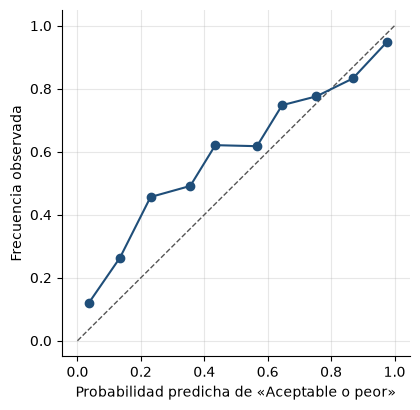

Error de calibración esperado (ECE): 0.075


,prob_predicha_media,frecuencia_observada,dias
0,0.035,0.119,1250
1,0.134,0.264,629
2,0.231,0.456,515
3,0.356,0.491,466
4,0.435,0.621,306
5,0.566,0.618,442
6,0.645,0.748,226
7,0.754,0.776,598
8,0.869,0.833,747
9,0.977,0.949,2503


In [9]:
p_no_buena = nb_modelo.predict_proba(X_te)[:, 1:].sum(axis=1)
real = y_te >= 1
bordes = np.linspace(0, 1, 11)
grupo = np.clip(np.digitize(p_no_buena, bordes) - 1, 0, 9)
calibracion = pd.DataFrame({"prob_predicha_media": pd.Series(p_no_buena).groupby(grupo).mean(),
                            "frecuencia_observada": pd.Series(real).groupby(grupo).mean(),
                            "dias": pd.Series(real).groupby(grupo).size()})
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], color="#555", ls="--", lw=1)
ax.plot(calibracion["prob_predicha_media"], calibracion["frecuencia_observada"], "o-", color="#1F4E79")
ax.set_xlabel("Probabilidad predicha de «Aceptable o peor»"); ax.set_ylabel("Frecuencia observada")
plt.show()
error = float((np.abs(calibracion["prob_predicha_media"] - calibracion["frecuencia_observada"]) * calibracion["dias"]).sum() / calibracion["dias"].sum())
print(f"Error de calibración esperado (ECE): {error:.3f}")
calibracion.round(3)

**Lectura.** En la zona alta las probabilidades son fiables (dice 0.98 y ocurre 0.95). En la zona baja el modelo es sobreconfiado: cuando da menos del 50 % a «Aceptable o peor», ocurre entre 8 y 22 puntos más de lo que dice. Es el efecto esperado de Naive Bayes al contar dos veces evidencia correlacionada, y se suma a que 2025 tuvo otra proporción de días buenos que los años de entrenamiento. Para un uso real habría que recalibrar las probabilidades.

## 8. Exactitud por estación

In [10]:
por_estacion = pd.DataFrame(metricas["por_estacion"]).assign(diferencia=lambda d: (d["naive_bayes"] - d["persistencia"]).round(4)).sort_values("diferencia", ascending=False)
print(f"Estaciones en que el Naive Bayes supera a la persistencia: {(por_estacion['diferencia'] > 0).sum()} de {len(por_estacion)}")
por_estacion

Estaciones en que el Naive Bayes supera a la persistencia: 17 de 23


,estacion,n,naive_bayes,persistencia,diferencia
21,UNIVERSIDAD CES,314,0.7771,0.7325,0.0446
12,I.E. PEDRO JUSTO B.,337,0.8902,0.8457,0.0445
0,ALMACÉN GENERAL DE EPM,311,0.8167,0.7846,0.0321
3,CASA JUSTICIA,331,0.8792,0.8520,0.0272
22,VILLAHERMOSA,339,0.7522,0.7257,0.0265
2,BIBLIOTECA FERNANDO B.,331,0.7160,0.6918,0.0242
10,I.E. CONCEJO MUNICIPAL,346,0.8497,0.8324,0.0173
6,FISCALÍA SECTOR CARIBE,330,0.8333,0.8182,0.0151
9,I.E. CIRO MENDIA,336,0.7738,0.7589,0.0149
16,PARQUE BIBLIOTECA TOMÁS CARRASQUILLA - LA QUINTANA,347,0.7435,0.7291,0.0144


## 9. Limitaciones del modelo

- **La mejora sobre la persistencia es pequeña.** El intervalo de la sección 3 dice cuánta confianza merece.
- **Episodios.** El año de prueba casi no tiene días de episodio, así que la capacidad de anticiparlos solo se observa en validación, con cifras optimistas. Además casi todos los episodios de los datos son de una sola temporada (febrero-abril de 2024).
- **Independencia condicional.** Naive Bayes supone que las variables son independientes dada la clase. El nivel de hoy y el de la semana están correlacionados, así que parte de la evidencia se cuenta dos veces.
- **Sin meteorología.** No se usan lluvia, viento ni altura de la capa de mezcla, que son los factores físicos que disparan o disipan un episodio. El modelo solo ve la inercia del propio PM2.5, el día de la semana y la tendencia regional.
- **Datos.** En 2022 y 2023 solo hay 9 estaciones utilizables, por el defecto de la fuente descrito en `01_eda.ipynb`. Solo se predice cuando hay promedio válido el día de referencia. Los festivos se tratan como días laborales.
- **Un solo periodo de prueba.** 2025 fue un año limpio y puede no representar a los siguientes.

El modelo es un apoyo analítico con fines académicos y no reemplaza el pronóstico oficial del SIATA.